# Vrije val
## General
**Name:** Youri Israel en Pim van der Heijden  
**Title of the experiment:** Een nauwkeurige en precieze bepaling van $g$ met een vrije val  
**Starting date:** 24/11/2026  
**Expected enddate:**  
**Partner:** Youri Israel / Pim van der Heijden  
**Goal of the experiment:** De zwaartekrachtsversnelling $g$ bepalen tot op het vierde significante cijfer, met een onzekerheid kleiner dan $0{,}5\,\%$ van de waarde in Delft.  
**Research question:** Welke waarde van $g$ (met onzekerheid) volgt uit de valtijd van een kogel tussen twee lichtpoortjes, gemeten voor verschillende valhoogtes, en is die waarde in overeenstemming met de waarde in Delft?  
**Expectations or Hypothesis:** De valhoogte neemt kwadratisch toe met de valtijd. Verwacht wordt dat de gemeten $g$ binnen de onzekerheid overeenkomt met $g_\mathrm{Delft} = 9{,}812\ldots\,\mathrm{m/s^2}$. Door de luchtweerstand kan de gemeten waarde een klein beetje (orde $0{,}2\,\%$) te laag uitvallen.  
**Desired accuracy:** $u(g)/g < 0{,}5\,\%$, dus $u(g) < 0{,}05\,\mathrm{m/s^2}$.


In [1]:
#import necessary libraries
import matplotlib.pyplot as plt
import numpy as np
import math
from scipy.optimize import curve_fit
from scipy.integrate import solve_ivp

g_ref = 9.812   # m/s^2, waarde in Delft uit de handleiding (vul eventueel meer cijfers in)

## Preparation


**Assignments:**

---
### Opdracht 1 – Software
Arduino IDE geïnstalleerd en `freefall.ino` gedownload. De code wacht tot detectiepin 2 (pin 8, bovenste poortje) onderbroken wordt en slaat dan `time1 = micros()` op. Daarna wacht hij op detectiepin 1 (pin 2, onderste poortje) en slaat `time2` op. Het verschil `time2 - time1` (in $\mu$s) wordt naar de seriële monitor gestuurd (baudrate 9600).

### Opdracht 2–5 – Testrun met de stopwatch (valhoogte 1,0 m)
De metingen staan in de codecel hieronder: eerst 5 metingen, daarna 10 metingen. Voor elke serie worden het gemiddelde $\bar t$, de standaarddeviatie $s$ en de onzekerheid van het gemiddelde $u(\bar t) = s/\sqrt{N}$ berekend.

*(Nog invullen na de testrun.)*

### Opdracht 6 – Effect van 10 in plaats van 5 metingen
De standaarddeviatie $s$ zegt hoeveel één meting spreidt; die wordt niet kleiner als je vaker meet. De onzekerheid van het gemiddelde is $s/\sqrt{N}$ en wordt dus een factor $\sqrt{10/5} \approx 1{,}4$ kleiner. Bij de slinger is dat anders: daar meet je 10 periodes in één keer, zodat de reactietijdfout over 10 periodes wordt verdeeld (factor 10). Bij de vrije val kan dat niet, want elke val is één los tijdsinterval.

### Opdracht 7 – Is de stopwatch nauwkeurig genoeg?
Uit $h = \tfrac12 g t^2$ volgt $g = 2h/t^2$ en
$$\frac{u(g)}{g} = \sqrt{\left(\frac{u(h)}{h}\right)^2 + \left(2\,\frac{u(t)}{t}\right)^2}.$$
Bij $h = 1{,}0\,\mathrm{m}$ is $t \approx 0{,}45\,\mathrm{s}$. Met $u(h) = 1\,\mathrm{mm}$ ($0{,}1\,\%$) moet $u(t) \lesssim 1\,\mathrm{ms}$ zijn (zie codecel). De reactietijd bij een stopwatch is ongeveer $0{,}1$ tot $0{,}2\,\mathrm{s}$ en spreidt minstens enkele honderdsten van een seconde. Bij een spreiding van 0,05 s zou je ongeveer 2000 metingen nodig hebben, en een systematische reactietijd middelt er helemaal niet uit. **De stopwatch is dus niet geschikt**; daarom gebruiken we de Arduino met lichtpoortjes ($\mu$s-resolutie).

### Opdracht 8 – Spreiding met de Arduino
*(Nog invullen: meet 10 keer bij 1,0 m met de Arduino en vergelijk $s$ en $u(\bar t)$ met de stopwatchmetingen.)*

### Opdracht 9 – Wat ontbreekt er aan de theorie?
De formule $y(t) = y_0 + v_0 t + \tfrac12 g t^2$ geldt alleen in vacuüm, voor een puntmassa, met een perfecte tijdmeting. Wat er ontbreekt:
1. **Beginsnelheid.** De klok start bij het bovenste poortje. De kogel heeft daar al snelheid $v_0 \neq 0$. $v_0$ moet dus een fitparameter zijn, en hij moet bij elke val gelijk zijn: laat de kogel steeds van hetzelfde punt boven het bovenste poortje los.
2. **Luchtweerstand.** Er werkt een kracht $F_w = \tfrac12 \rho C_d A v^2$ tegen de beweging in, zodat $m\ddot y = mg - \tfrac12\rho C_d A \dot y^2$. Volgens de simulatie hieronder maakt dat voor een stalen kogel van 2 cm de gefitte $g$ ongeveer $0{,}2\,\%$ te laag. Dat is niet verwaarloosbaar ten opzichte van $0{,}5\,\%$. Gebruik dus een zware, kleine kogel en corrigeer eventueel.
3. **Wat de hoogte precies is.** $h$ is de afstand tussen de twee lichtbundels, niet tussen de randen van de houders. Beide poortjes moeten door dezelfde kant van de kogel (de onderkant) getriggerd worden. Een vaste fout in de hoogtemeting kun je opvangen met een extra fitparameter $h_0$.
4. **Tijdmeting.** De Arduino-klok kan een kleine relatieve afwijking hebben (kristal/resonator). Die werkt twee keer zo sterk door in $g$. Een vaste vertraging van de sensoren valt weg in het verschil $t_2 - t_1$ als beide poortjes even snel reageren.
5. **Uitlijning.** De poortjes moeten recht onder elkaar staan (schietlood), zodat de kogel beide bundels door het midden onderbreekt en verticaal valt.

### Opdracht 10 – Meetplan
Zie *Method* en *Procedure* hieronder. Kort samengevat:
- **Variëren van de hoogte:** $h = 0{,}20$ tot $1{,}00\,\mathrm{m}$ in stappen van $0{,}10\,\mathrm{m}$ (9 hoogtes). Met meerdere hoogtes kun je het model controleren (kwadratisch verband, residuen) en $v_0$ (en eventueel $h_0$) uit de data fitten, in plaats van ze aan te nemen. Een groot bereik in $h$ maakt de fit nauwkeuriger.
- **Herhalen:** 10 vallen per hoogte. Daarmee bepalen we de spreiding $s$ en $u(\bar t) = s/\sqrt{10}$.
- **Loslaten:** steeds vanaf hetzelfde punt, ongeveer 3 cm boven het bovenste poortje (met een vaste klem of mal), zodat $v_0$ voor alle metingen gelijk is. Alleen het onderste poortje wordt verschoven.
- **Hoogte meten:** met een rolmaat tussen de lichtbundels, $u(h) \approx 1\,\mathrm{mm}$.
- **Aannames valideren:** luchtweerstand (simulatie), constante $v_0$ (spreiding in $t$ per hoogte), nauwkeurigheid van de Arduino-klok (vergelijk 60 s Arduino-tijd met een referentieklok), lineaire residuen.

### Opdracht 11 – Controle meetplan
*(Nog invullen: opmerkingen van de assistent.)*

### Opdracht 12 – Verwerking in Python
De verwerking staat in de functie `verwerk()` hieronder. Die is getest op gesimuleerde data, zodat zeker is dat de verwerking de juiste $g$ teruggeeft.

Daarna volgt een schatting van de haalbare nauwkeurigheid. Die laat zien dat $0{,}5\,\%$ krap is: met $u(h) = 1\,\mathrm{mm}$ per hoogte en een spreiding van $1\,\mathrm{ms}$ per val kom je net boven $0{,}5\,\%$ uit. De hoogte moet dus zorgvuldig gemeten worden (liefst $\leq 0{,}5\,\mathrm{mm}$), en de spreiding van de Arduino (opdracht 8) bepaalt of 10 vallen per hoogte genoeg is of dat er meer hoogtes nodig zijn.


In [2]:
# Opdracht 2-5: testrun met de stopwatch bij h = 1,0 m (tijden in s)
t_stopwatch_5  = np.array([])   # 5 metingen invullen
t_stopwatch_10 = np.array([])   # 10 metingen invullen

def statistiek(t):
    # gemiddelde, standaarddeviatie en onzekerheid van het gemiddelde
    N = len(t)
    gem = np.mean(t)
    s = np.std(t, ddof=1)
    return gem, s, s/np.sqrt(N)

for naam, t in [('5 metingen', t_stopwatch_5), ('10 metingen', t_stopwatch_10)]:
    if len(t) > 1:
        gem, s, u = statistiek(t)
        print(f"{naam}: t = {gem:.3f} s, s = {s:.3f} s, u(t_gem) = {u:.3f} s")
    else:
        print(f"{naam}: nog geen data")

5 metingen: nog geen data
10 metingen: nog geen data


In [3]:
# Opdracht 7: welke onzekerheid in t is nodig voor u(g)/g = 0,5 %?
h, u_h = 1.0, 0.001                     # m
t = np.sqrt(2*h/g_ref)
rel_max = 0.005
u_t_max = t/2*np.sqrt(rel_max**2 - (u_h/h)**2)
print(f"t = {t:.3f} s,  u(t) mag maximaal {1e3*u_t_max:.2f} ms zijn")
print(f"Met een spreiding van 0,05 s (stopwatch) zijn dan {(0.05/u_t_max)**2:.0f} metingen nodig")

t = 0.451 s,  u(t) mag maximaal 1.11 ms zijn
Met een spreiding van 0,05 s (stopwatch) zijn dan 2044 metingen nodig


In [4]:
# Opdracht 9: validatie van de aanname 'luchtweerstand verwaarloosbaar'
# Simuleer een val met luchtweerstand en fit daarna het model zonder luchtweerstand.
rho_lucht, Cd = 1.2, 0.47               # kg/m^3, weerstandscoefficient bol

def simuleer_val(h, d, rho_kogel, g=g_ref, h_los=0.03):
    # valtijden tussen poortje 1 en 2 voor hoogtes h; kogel losgelaten h_los boven poortje 1
    m = rho_kogel*np.pi*d**3/6
    k = 0.5*rho_lucht*Cd*np.pi*d**2/4/m
    sol = solve_ivp(lambda t, y: [y[1], g - k*y[1]**2], [0, 2], [0, 0],
                    dense_output=True, rtol=1e-11, atol=1e-13)
    tt = np.linspace(0, 2, 400001)
    y = sol.sol(tt)[0]
    t1 = np.interp(h_los, y, tt)
    return np.interp(h_los + h, y, tt) - t1

def model(t, v0, g):
    return v0*t + 0.5*g*t**2

h_test = np.linspace(0.2, 1.0, 9)
for d, materiaal, rho_k in [(0.019, 'staal', 7850), (0.025, 'staal', 7850), (0.030, 'hout', 700)]:
    t_sim = simuleer_val(h_test, d, rho_k)
    (v0_f, g_f), _ = curve_fit(model, t_sim, h_test, p0=[0.7, 9.8])
    print(f"{materiaal}, d = {100*d:.1f} cm: gefitte g = {g_f:.4f} m/s^2 ({100*(g_f/g_ref-1):+.2f} %)")

staal, d = 1.9 cm: gefitte g = 9.7910 m/s^2 (-0.21 %)
staal, d = 2.5 cm: gefitte g = 9.7960 m/s^2 (-0.16 %)
hout, d = 3.0 cm: gefitte g = 9.6637 m/s^2 (-1.51 %)


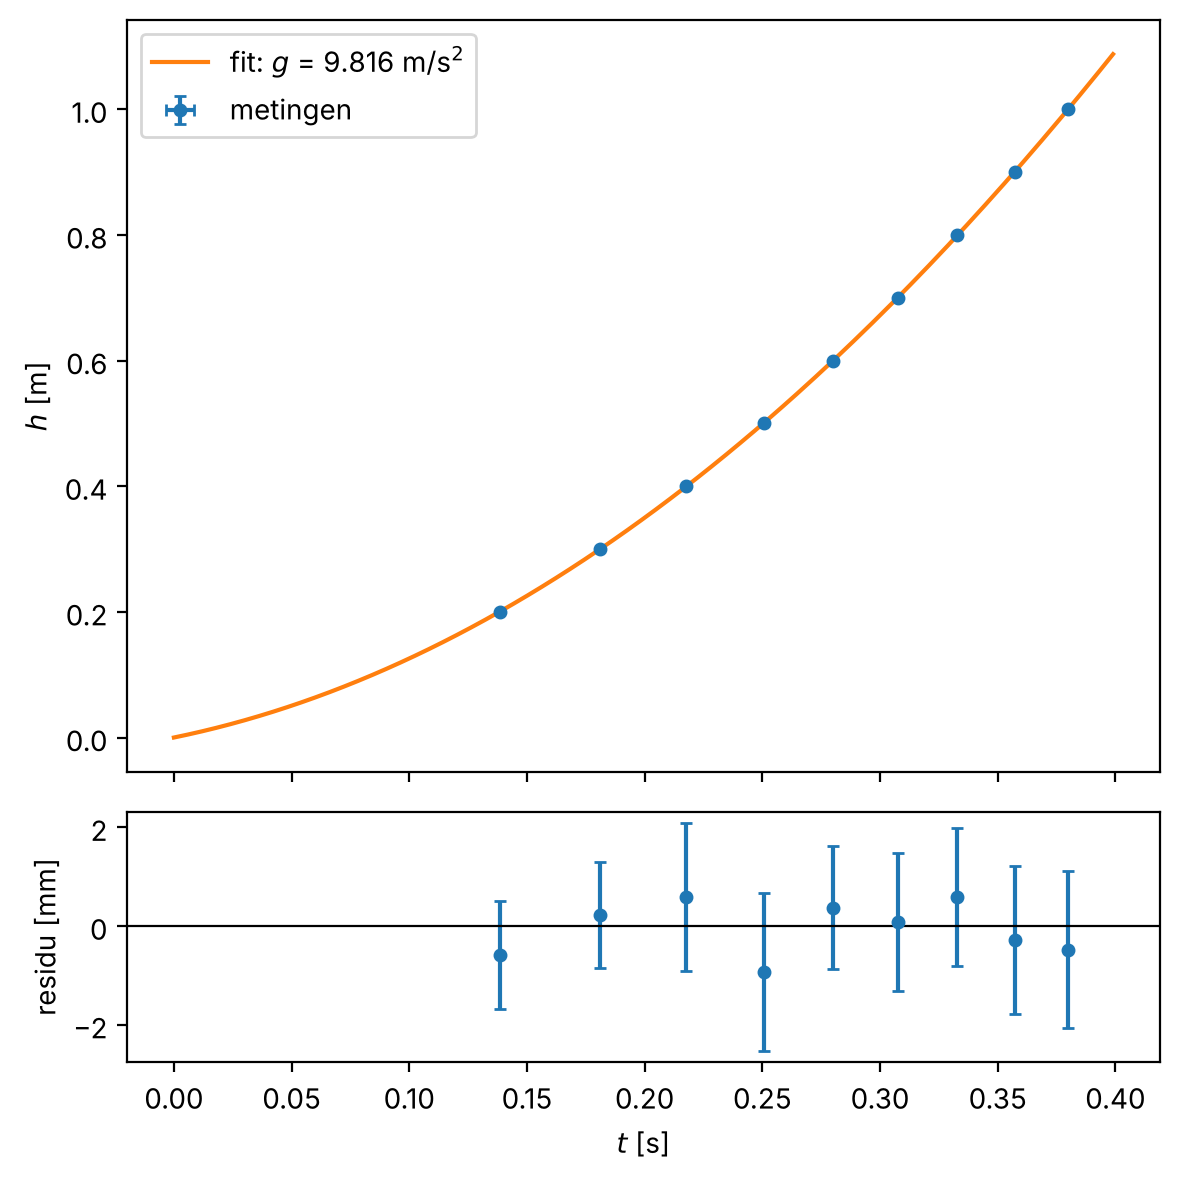

Test: g = 9.8164 ± 0.0491 m/s^2 (ingevoerd: 9.812), chi2_red = 0.17


In [5]:
# Opdracht 12: de verwerking
def verwerk(h, t_metingen, u_h, plot=True):
    # h: hoogtes [m]; t_metingen: lijst met per hoogte een array valtijden [s]; u_h: onzekerheid h [m]
    t_gem = np.array([np.mean(t) for t in t_metingen])
    u_t   = np.array([np.std(t, ddof=1)/np.sqrt(len(t)) for t in t_metingen])

    # eerste fit alleen met u(h), daarna effectieve variantie: u_eff^2 = u_h^2 + (dh/dt * u_t)^2
    sigma = np.full_like(h, u_h, dtype=float)
    p, cov = curve_fit(model, t_gem, h, p0=[0.7, 9.8], sigma=sigma, absolute_sigma=True)
    for _ in range(3):
        sigma = np.sqrt(u_h**2 + ((p[0] + p[1]*t_gem)*u_t)**2)
        p, cov = curve_fit(model, t_gem, h, p0=p, sigma=sigma, absolute_sigma=True)
    v0, g = p
    u_v0, u_g = np.sqrt(np.diag(cov))
    res = h - model(t_gem, *p)
    chi2red = np.sum((res/sigma)**2)/(len(h) - 2)

    if plot:
        fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(6, 6), sharex=True,
                                       gridspec_kw={'height_ratios': [3, 1]})
        tt = np.linspace(0, 1.05*t_gem.max(), 200)
        ax1.errorbar(t_gem, h, xerr=u_t, yerr=u_h, fmt='o', ms=4, capsize=2, label='metingen')
        ax1.plot(tt, model(tt, *p), label=f'fit: $g$ = {g:.3f} m/s$^2$')
        ax1.set_ylabel('$h$ [m]'); ax1.legend()
        ax2.errorbar(t_gem, 1e3*res, yerr=1e3*sigma, fmt='o', ms=4, capsize=2)
        ax2.axhline(0, color='k', lw=0.8)
        ax2.set_xlabel('$t$ [s]'); ax2.set_ylabel('residu [mm]')
        plt.tight_layout(); plt.show()

    return dict(g=g, u_g=u_g, v0=v0, u_v0=u_v0, chi2red=chi2red, t_gem=t_gem, u_t=u_t)

# Test van de verwerking met GESIMULEERDE data (geen echte metingen!):
# stalen kogel 2,5 cm, zonder luchtweerstand, 10 vallen per hoogte met 1 ms ruis
rng = np.random.default_rng(1)
t_echt = simuleer_val(h_test, 0.025, 1e9)     # enorme dichtheid = geen luchtweerstand
t_sim = [ti + rng.normal(0, 1e-3, 10) for ti in t_echt]
r = verwerk(h_test, t_sim, u_h=0.001)
print(f"Test: g = {r['g']:.4f} ± {r['u_g']:.4f} m/s^2 (ingevoerd: {g_ref}), chi2_red = {r['chi2red']:.2f}")

In [6]:
# Opdracht 10/12: verwachte nauwkeurigheid van g voor verschillende keuzes
# s_t = spreiding van een losse val, N = vallen per hoogte, n_h = aantal hoogtes tussen 0,2 en 1,0 m
v0_verw = np.sqrt(2*g_ref*0.03)     # kogel 3 cm boven het bovenste poortje losgelaten
print(" n_h   N   u_h [mm]  s_t [ms]   u(g)/g [%]")
for n_h in [9, 17]:
    for N in [10, 20]:
        for u_hh in [1e-3, 5e-4]:
            for s_t in [1e-3, 1e-4]:
                hh = np.linspace(0.2, 1.0, n_h)
                tt = (-v0_verw + np.sqrt(v0_verw**2 + 2*g_ref*hh))/g_ref
                sig = np.sqrt(u_hh**2 + ((v0_verw + g_ref*tt)*s_t/np.sqrt(N))**2)
                _, c = curve_fit(model, tt, hh, p0=[v0_verw, g_ref], sigma=sig, absolute_sigma=True)
                print(f"{n_h:4d} {N:3d}   {1e3*u_hh:6.1f}    {1e3*s_t:6.1f}     {100*np.sqrt(c[1,1])/g_ref:6.2f}")

 n_h   N   u_h [mm]  s_t [ms]   u(g)/g [%]
   9  10      1.0       1.0       0.55
   9  10      1.0       0.1       0.38
   9  10      0.5       1.0       0.43
   9  10      0.5       0.1       0.20
   9  20      1.0       1.0       0.47
   9  20      1.0       0.1       0.38
   9  20      0.5       1.0       0.33
   9  20      0.5       0.1       0.19
  17  10      1.0       1.0       0.41
  17  10      1.0       0.1       0.29
  17  10      0.5       1.0       0.32
  17  10      0.5       0.1       0.15
  17  20      1.0       1.0       0.36
  17  20      1.0       0.1       0.29
  17  20      0.5       1.0       0.25
  17  20      0.5       0.1       0.15


**Method:** Een stalen kogel valt door twee lichtpoortjes die verticaal boven elkaar staan. De Arduino meet de tijd tussen het onderbreken van het bovenste en het onderste poortje. Deze valtijd wordt gemeten voor 9 verschillende afstanden $h$ tussen de poortjes, telkens 10 keer. Aan $h(t)$ wordt een model gefit, waaruit $g$ volgt.

**Theory:**  

Wanneer je een object laat vallen in vacuüm zal het object een beweging beschreven volgens:

$$ y(t) = y_0 + v_0t+\frac{gt^2}{2}$$

Kies $y$ positief naar beneden en $t = 0$ op het moment dat de kogel het bovenste poortje passeert ($y_0 = 0$). Op dat moment heeft de kogel al een snelheid $v_0$, want hij wordt een stukje boven het poortje losgelaten. De afstand $h$ tot het onderste poortje wordt afgelegd in een tijd $t$ met

$$h = v_0 t + \tfrac12 g t^2. \tag{1}$$

Door de valtijd voor verschillende hoogtes te bepalen, volgen $v_0$ en $g$ uit een fit van vergelijking (1). Als $v_0$ voor elke val gelijk is, hoeft die niet apart gemeten te worden.

*Luchtweerstand.* In lucht geldt eigenlijk $m\ddot y = mg - \tfrac12 \rho C_d A \dot y^2$. Voor een zware, kleine kogel is dit effect klein, maar volgens de simulatie bij opdracht 9 nog ongeveer $0{,}2\,\%$. Daarom kiezen we een stalen kogel en bespreken we de correctie.

*Onzekerheden.* Per hoogte is $u(\bar t) = s/\sqrt{N}$. Omdat zowel $h$ als $t$ onzekerheden hebben, wordt de effectieve-variantiemethode gebruikt:
$$\sigma_\mathrm{eff}^2 = u(h)^2 + \left(\frac{dh}{dt}\,u(\bar t)\right)^2 = u(h)^2 + \bigl((v_0 + g t)\,u(\bar t)\bigr)^2.$$

*Strijdigheidsanalyse.* De gemeten waarde is in overeenstemming met $g_\mathrm{Delft}$ als
$$|g - g_\mathrm{Delft}| < 2\sqrt{u(g)^2 + u(g_\mathrm{Delft})^2},$$
waarbij $u(g_\mathrm{Delft})$ verwaarloosbaar klein is.

**Independent variable:** valhoogte $h$ (afstand tussen de lichtbundels)  
**Dependent variable:** valtijd $t$ tussen de twee poortjes  
**Controlled variablen:** loslaatpunt boven het bovenste poortje (dus $v_0$), de kogel (massa en diameter), de uitlijning van de poortjes  
**Measurement instruments \& Settings:** Arduino met twee lichtpoortjes en `freefall.ino` (tijd met `micros()`, resolutie $4\,\mu\mathrm{s}$, baudrate 9600); rolmaat (resolutie $1\,\mathrm{mm}$); schuifmaat en weegschaal voor de kogel; schietlood voor de uitlijning  
**Procedure:**
1. Upload `freefall.ino` naar de Arduino, kies de juiste poort en open de seriële monitor (9600 baud).
2. Zet het statief met de poortjes recht en lijn ze met een schietlood uit, zodat de kogel door het midden van beide bundels valt.
3. Meet de diameter en massa van de kogel.
4. Zet een vaste loslaatklem ongeveer 3 cm boven het bovenste poortje. Dit punt verandert tijdens de hele meting niet.
5. Zet het onderste poortje op $h = 0{,}20\,\mathrm{m}$ en meet $h$ met de rolmaat tussen de lichtbundels.
6. Laat de kogel 10 keer vallen en noteer de tijden uit de seriële monitor. Noteer bijzonderheden (bijv. kogel raakt het poortje).
7. Herhaal stap 5 en 6 voor $h = 0{,}30, 0{,}40, \ldots, 1{,}00\,\mathrm{m}$.
8. Controleer de Arduino-klok: laat de Arduino een tijd van ongeveer 60 s meten en vergelijk die met een referentieklok.

**Setup(drawing or picture):**  
*(Nog toevoegen: foto of schets van statief, poortjes, loslaatpunt en Arduino.)*

**Notes:**  
- Bovenste poortje = detectiepin 2 (pin 8, start), onderste poortje = detectiepin 1 (pin 2, stop).
- De Arduino geeft de tijd in $\mu$s.

**About accuracy:** De onzekerheid in $t$ komt uit de spreiding van de 10 metingen per hoogte (de resolutie van $4\,\mu\mathrm{s}$ is verwaarloosbaar). De onzekerheid in $h$ is ongeveer $1\,\mathrm{mm}$ (aflezen van de rolmaat en de positie van de lichtbundel). Volgens de schatting bij opdracht 12 is $0{,}5\,\%$ alleen haalbaar als $u(h) \lesssim 0{,}5\,\mathrm{mm}$ en de spreiding in $t$ klein is (orde $0{,}1\,\mathrm{ms}$). Na de testmetingen (opdracht 8) worden het aantal hoogtes en het aantal vallen per hoogte daarop aangepast. Systematische effecten (luchtweerstand, klokafwijking) worden apart geschat.


## Execution

In [7]:
# Measurements: Explain the names of variables provide only raw data in np.arrays!
# Kogel
d_kogel = None      # diameter kogel [m]
m_kogel = None      # massa kogel [kg]

# h: afstand tussen de lichtbundels [m], u_h: onzekerheid in h [m]
h = np.array([])    # bijv. [0.20, 0.30, ..., 1.00]
u_h = 0.001

# t_us: valtijden uit de seriele monitor in microseconden, een array per hoogte (zelfde volgorde als h)
t_us = [
    # np.array([...10 waarden...]),   # h = 0,20 m
]

# Klokcontrole: door de Arduino gemeten tijd en referentietijd [s]
t_arduino_ref = None
t_referentie  = None

**Observations:**  
**Notes:**  

## Processing
**Description of processing of raw data into scientific evidence:**
1. De tijden worden omgerekend van $\mu$s naar s.
2. Per hoogte worden $\bar t$, $s$ en $u(\bar t) = s/\sqrt{N}$ berekend.
3. Vergelijking (1) wordt gefit aan $h(\bar t)$ met de effectieve-variantiemethode (functie `verwerk()`), met $v_0$ en $g$ als vrije parameters.
4. De residuen en $\chi^2_\mathrm{red}$ laten zien of het model past.
5. $g$ wordt vergeleken met $g_\mathrm{Delft}$ (strijdigheidsanalyse).
6. Systematische effecten (luchtweerstand, klokafwijking) worden geschat met de gemeten kogel en de klokcontrole.


In [8]:
#Data processing and analysis: tijden per hoogte
if len(h) > 0:
    t_metingen = [np.asarray(t)*1e-6 for t in t_us]   # us -> s
    for hi, t in zip(h, t_metingen):
        gem, s, u = statistiek(t)
        print(f"h = {hi:.3f} m:  t = {gem:.5f} s,  s = {1e3*s:.2f} ms,  u(t) = {1e3*u:.2f} ms  (N = {len(t)})")
else:
    print("Nog geen meetdata ingevuld")

Nog geen meetdata ingevuld


In [9]:
#Data processing and analysis: fit van h = v0*t + g*t^2/2
if len(h) > 0:
    r = verwerk(h, t_metingen, u_h)
    g, u_g = r['g'], r['u_g']
    print(f"g  = {g:.4f} ± {u_g:.4f} m/s^2  ({100*u_g/g:.2f} %)")
    print(f"v0 = {r['v0']:.3f} ± {r['u_v0']:.3f} m/s")
    print(f"chi2_red = {r['chi2red']:.2f}")

In [10]:
#Data processing and analysis: systematische effecten
if len(h) > 0 and d_kogel is not None and m_kogel is not None:
    # luchtweerstand voor de gebruikte kogel (zelfde simulatie als bij opdracht 9)
    rho_k = m_kogel/(np.pi*d_kogel**3/6)
    t_sim = simuleer_val(h, d_kogel, rho_k, h_los=r['v0']**2/(2*g_ref))
    (_, g_sim), _ = curve_fit(model, t_sim, h, p0=[0.7, 9.8])
    corr_lucht = g_ref/g_sim
    print(f"Luchtweerstand: gefitte g is {100*(g_sim/g_ref-1):+.3f} % -> correctiefactor {corr_lucht:.5f}")
if t_arduino_ref is not None and t_referentie is not None:
    eps = t_arduino_ref/t_referentie - 1
    print(f"Arduino-klok wijkt {100*eps:+.3f} % af -> effect op g: {-200*eps:+.3f} %")

**Describing the pattern in the processed data:**  
*(Nog invullen: liggen de punten op de parabool, zijn de residuen willekeurig verdeeld rond 0?)*


In [11]:
#Calculations of e.a. measurement uncertainties, and providing final answers.
if len(h) > 0:
    verschil = abs(g - g_ref)
    grens = 2*u_g
    print(f"g = {g:.3f} ± {u_g:.3f} m/s^2,  g_Delft = {g_ref} m/s^2")
    print(f"|g - g_Delft| = {verschil:.4f} m/s^2, grens 2u = {grens:.4f} m/s^2 -> "
          + ("in overeenstemming" if verschil < grens else "strijdig"))
    print(f"Doel u(g)/g < 0,5 %: {'gehaald' if u_g/g < 0.005 else 'niet gehaald'} ({100*u_g/g:.2f} %)")

**Notes:**  

## Discussion

*(Nog invullen na de metingen.)* Punten om te bespreken:
- Ligt $g$ binnen $2u$ van $g_\mathrm{Delft}$? Zo niet: welke systematische fout verklaart het verschil?
- Luchtweerstand: hoe groot is de correctie voor de gebruikte kogel en verandert die de conclusie?
- Was $v_0$ constant? (spreiding in $t$ per hoogte, waarde van $v_0$ uit de fit vergeleken met $\sqrt{2 g h_\mathrm{los}}$)
- Afwijking van de Arduino-klok.
- $\chi^2_\mathrm{red}$: zijn de onzekerheden realistisch?
- Uitlijning en de bepaling van $h$ tussen de lichtbundels.


## Conclusion

*(Nog invullen: waarde van $g$ met onzekerheid, wel of niet in overeenstemming met $g_\mathrm{Delft}$, is de $0{,}5\,\%$ gehaald?)*

## Additional notes, remarks, explanations, thoughts etc